# Project 10: Overfitting and Underfitting Analysis

**Dataset:** Iris dataset  
**Objective:** Build neural networks with different levels of complexity, evaluate them using the same training and testing data, and identify underfitting, appropriate fitting, and overfitting.

## Introduction
Underfitting happens when a model is too simple to learn the patterns in the data. Overfitting happens when a model learns the training data too closely and performs worse on unseen data. A well-fitted model performs well on both training and testing data.

## Task 1: Load the dataset and prepare the data
We use the Iris dataset, which contains four flower measurements and three species/classes. We use one fixed train-test split for all models so that the comparison is fair.

In [2]:
# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.neural_network import MLPClassifier

# Load Iris dataset
iris = load_iris()
X = iris.data
y = iris.target

print("Dataset shape:", X.shape)
print("Feature names:", iris.feature_names)
print("Class names:", iris.target_names)
print("Number of samples:", len(y))

Dataset shape: (150, 4)
Feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Class names: ['setosa' 'versicolor' 'virginica']
Number of samples: 150


### Prepare training and testing data
We split the dataset into 80% training data and 20% testing data. The same split is used for every model. Standardization helps neural networks train more effectively. The scaler is fitted only on the training set to avoid data leakage.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 120
Testing samples: 30


## Task 1: Build neural network models of different complexity

We compare three models:
1. **Simple model (2 neurons):** intentionally low capacity; may underfit.
2. **Medium model (10 neurons):** moderate capacity; may fit the patterns well.
3. **Complex model (100 neurons across two layers):** higher capacity; may overfit, although overfitting is not guaranteed on every dataset.

We use the same solver, training data, and test data for all models.

In [4]:
models = {
    "Simple (2 neurons)": MLPClassifier(
        hidden_layer_sizes=(2,), activation="relu", solver="lbfgs",
        max_iter=2000, random_state=42
    ),
    "Medium (10 neurons)": MLPClassifier(
        hidden_layer_sizes=(10,), activation="relu", solver="lbfgs",
        max_iter=2000, random_state=42
    ),
    "Complex (100, 100 neurons)": MLPClassifier(
        hidden_layer_sizes=(100, 100), activation="relu", solver="adam",
        max_iter=3000, random_state=42, alpha=0.00001
    )
}

results = []
trained_models = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    trained_models[name] = model

    train_pred = model.predict(X_train_scaled)
    test_pred = model.predict(X_test_scaled)

    train_acc = accuracy_score(y_train, train_pred)
    test_acc = accuracy_score(y_test, test_pred)

    results.append({
        "Model": name,
        "Training Accuracy": train_acc,
        "Testing Accuracy": test_acc,
        "Accuracy Gap": train_acc - test_acc
    })

results_df = pd.DataFrame(results)
results_df

,Model,Training Accuracy,Testing Accuracy,Accuracy Gap
0,Simple (2 neurons),0.983333,1.000000,-0.016667
1,Medium (10 neurons),1.000000,0.900000,0.100000
2,"Complex (100, 100 neurons)",1.000000,0.966667,0.033333


## Task 2: Train and evaluate the models

**Training accuracy** tells us how well the model predicts examples it learned from. **Testing accuracy** tells us how well it predicts unseen examples. A large gap between training and testing accuracy can indicate overfitting.

The exact scores are produced when you run the notebook. Results can vary slightly across software versions.

In [5]:
# Display accuracy as percentages
display_results = results_df.copy()
for col in ["Training Accuracy", "Testing Accuracy", "Accuracy Gap"]:
    display_results[col] = (display_results[col] * 100).round(2).astype(str) + "%"

display_results

,Model,Training Accuracy,Testing Accuracy,Accuracy Gap
0,Simple (2 neurons),98.33%,100.0%,-1.67%
1,Medium (10 neurons),100.0%,90.0%,10.0%
2,"Complex (100, 100 neurons)",100.0%,96.67%,3.33%


### Graph: Training vs Testing Accuracy
The bar chart compares the training and testing accuracy of the three models. Look for a model with low accuracy on both sets (possible underfitting) and a model with high training accuracy but noticeably lower testing accuracy (possible overfitting).

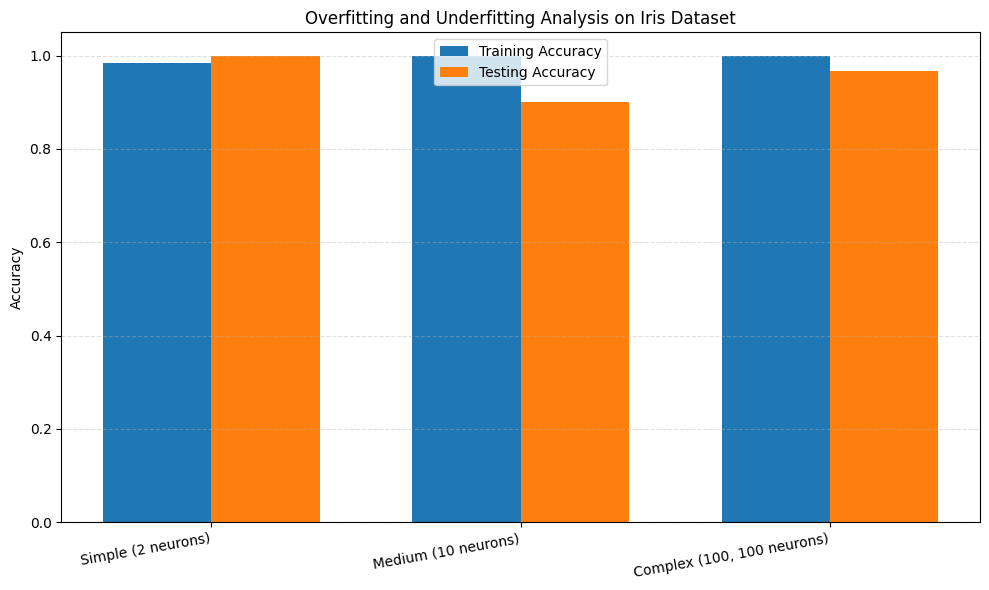

In [6]:
# Plot training and testing accuracy
x = np.arange(len(results_df))
width = 0.35

plt.figure(figsize=(10, 6))
plt.bar(x - width/2, results_df["Training Accuracy"], width, label="Training Accuracy")
plt.bar(x + width/2, results_df["Testing Accuracy"], width, label="Testing Accuracy")
plt.xticks(x, results_df["Model"], rotation=10, ha="right")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.title("Overfitting and Underfitting Analysis on Iris Dataset")
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

## Task 3: Identify fitting and suggest improvements

Use the accuracy table and graph to interpret the observed results. Do not label a model as overfitting or underfitting based only on its size.

- **Underfitting:** both training and testing accuracy are relatively low. The model is too simple or has not learned enough.
- **Appropriate fitting:** training and testing accuracy are both high and reasonably close.
- **Overfitting:** training accuracy is high but testing accuracy is noticeably lower.

### Automatically inspect the results
The code below gives a simple interpretation based on the measured accuracy gap. These are practical guidelines, not strict mathematical rules.

In [7]:
def interpret_model(row):
    train_acc = row["Training Accuracy"]
    test_acc = row["Testing Accuracy"]
    gap = row["Accuracy Gap"]

    if train_acc < 0.80 and test_acc < 0.80:
        return "Possible underfitting: both scores are low."
    elif gap >= 0.10:
        return "Possible overfitting: training score is much higher than testing score."
    elif train_acc >= 0.85 and test_acc >= 0.85 and abs(gap) < 0.10:
        return "Reasonably fitted: both scores are high and close."
    else:
        return "Mixed result: inspect both scores and the accuracy gap."

interpretations = results_df.copy()
interpretations["Interpretation"] = interpretations.apply(interpret_model, axis=1)
interpretations

,Model,Training Accuracy,Testing Accuracy,Accuracy Gap,Interpretation
0,Simple (2 neurons),0.983333,1.000000,-0.016667,Reasonably fitted: both scores are high and cl...
1,Medium (10 neurons),1.000000,0.900000,0.100000,Reasonably fitted: both scores are high and cl...
2,"Complex (100, 100 neurons)",1.000000,0.966667,0.033333,Reasonably fitted: both scores are high and cl...


### Ways to improve the models

**To reduce underfitting:**
- Increase the number of neurons or hidden layers.
- Train for more iterations when the model has not converged.
- Use informative input features.

**To reduce overfitting:**
- Reduce the number of neurons or hidden layers.
- Increase regularization (`alpha` in `MLPClassifier`).
- Collect more training examples or use cross-validation.
- Use early stopping where appropriate.

**To improve generalization:**
- Keep a separate test set.
- Fit preprocessing steps only on training data.
- Compare training and testing performance instead of relying on training accuracy alone.

## Result / Conclusion
In this experiment, neural networks with different architectures were trained on the Iris dataset using the same training and testing split. Their training accuracy, testing accuracy, and accuracy gap were compared using a table and graph. A low score on both sets suggests underfitting; a high training score with a substantially lower testing score suggests overfitting; and high, similar scores suggest appropriate fitting. The final classification depends on the actual results printed when the notebook is run.